In [ ]:
import matplotlib as mpl
import seaborn as sns
import importlib

# Seaborn theme
sns.set_theme(
    style="ticks",        # "white", "whitegrid", "ticks", "darkgrid"
    context="paper",       # notebook, paper, talk, poster
    palette="deep"
)

# Your publication formatting
mpl.rcParams.update({

    # Fonts
    "font.family": "Arial",
    "font.size": 14,

    # Figure titles
    "figure.titlesize": 34,
    "figure.titleweight": "bold",

    # Axes titles/labels
    "axes.titlesize": 14,
    "axes.labelsize": 14,

    # Tick labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,

    # Legend
    "legend.fontsize": 16,
    "legend.title_fontsize": 18,

    # Lines & markers
    "lines.linewidth": 3,
    "lines.markersize": 8,

    # Axes
    "axes.linewidth": 2,

    # Ticks
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "xtick.minor.width": 1.5,
    "ytick.minor.width": 1.5,

    # Grid
    "grid.linewidth": 1,
    "grid.alpha": 0.3,

    # Export
    "figure.dpi": 150,
    "savefig.dpi": 600,

    # Editable vector graphics
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [20]:
import biosensor_history_viewer
from biosensor_history_viewer import launch_history_viewer
importlib.reload(biosensor_history_viewer)

viewer = launch_history_viewer(
    "/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260806 Nanopore Geometry Sweep",
    figsize=(6, 6),
    ylim=(0.0, 0.125),
    xlim=(0.0, 1000.0),
)

In [5]:
# !python fit_1to1_kinetics.py \
#     --data-root "/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep" \
#     --output-csv "/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep/1to1_kinetics.csv"

Found 20 replicate history files.
[1/20] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep/concentration_1e-08M/replicate_001
    kon=1.148e+06 M^-1 s^-1, koff=0.117 s^-1, KD=101.9 nM, R2_assoc=0.1917, R2_diss=0.7445
[2/20] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep/concentration_1e-08M/replicate_002
    kon=9.193e+05 M^-1 s^-1, koff=0.09733 s^-1, KD=105.9 nM, R2_assoc=0.1356, R2_diss=0.9600
[3/20] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep/concentration_1e-08M/replicate_003
    kon=9.119e+05 M^-1 s^-1, koff=0.09211 s^-1, KD=101 nM, R2_assoc=0.1514, R2_diss=0.9276
[4/20] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep/concentration_1e-08M/repli

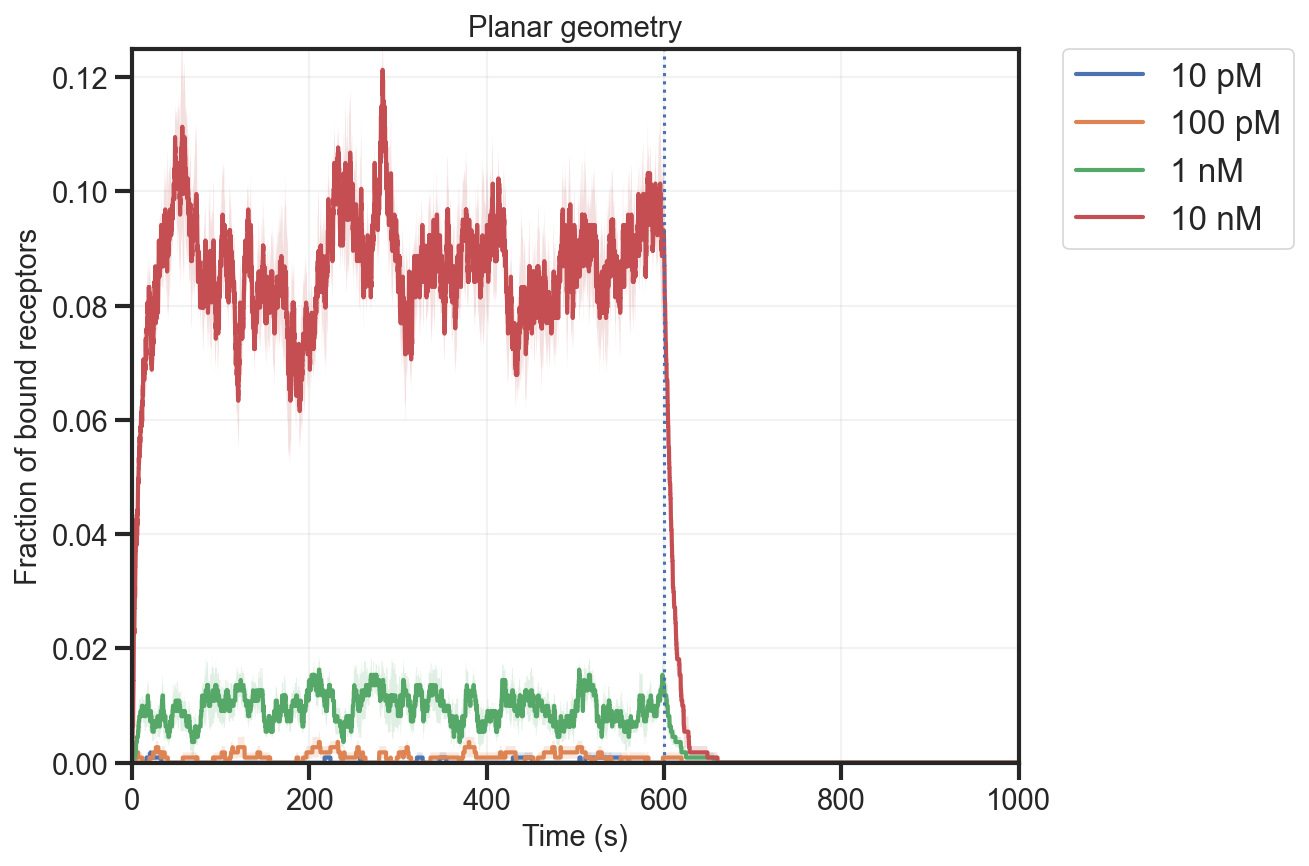

In [16]:
import plot_planar_concentration_sweep
importlib.reload(plot_planar_concentration_sweep)
from plot_planar_concentration_sweep import (
    load_concentration_sweep,
    plot_concentration_sweep,
)

data = load_concentration_sweep(
    "/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep"
)

fig, ax = plot_concentration_sweep(
    data,
    mode="mean",
    figsize=(9.0, 6),
    y_lim = (0.0, 0.125),
    x_lim = (0.0, 1000),
    title="Planar geometry",
)

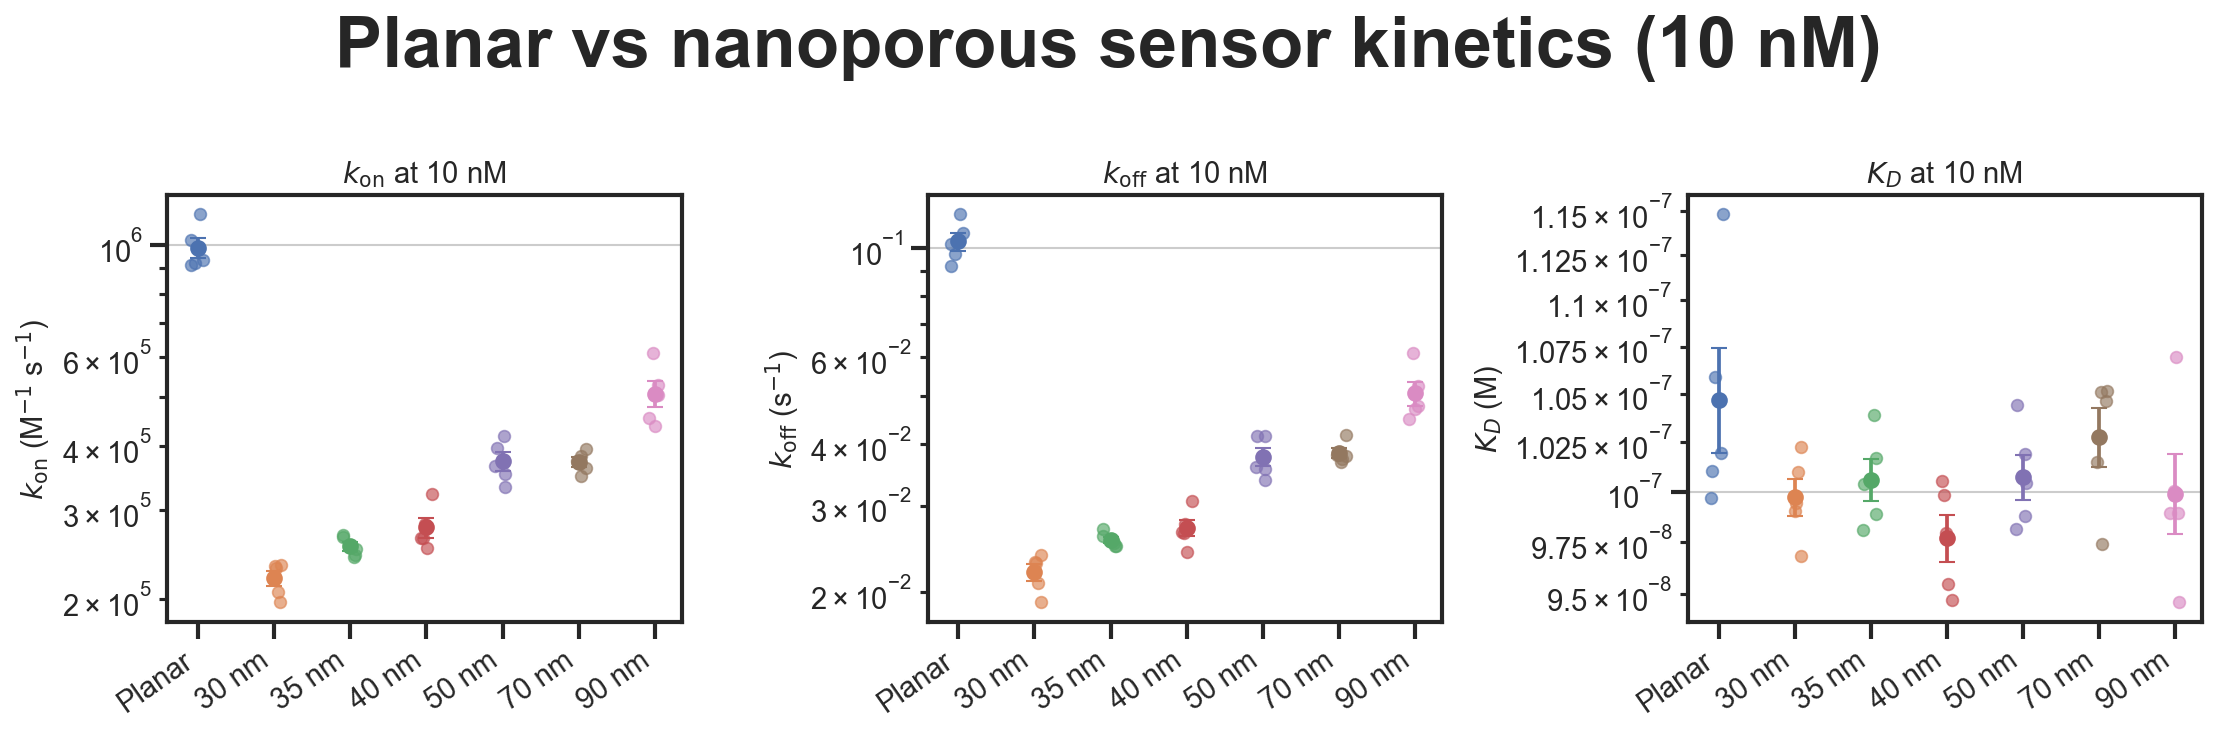

In [28]:
import compare_geometry_kinetics
importlib.reload(compare_geometry_kinetics)
from compare_geometry_kinetics import (
    load_geometry_comparison,
    plot_geometry_kinetics,
)

comparison = load_geometry_comparison(
    nanopore_csv="nanopore_1to1_kinetics.csv",
    planar_csv="planar_1to1_kinetics.csv",
    concentration_M=10e-9,
)

fig, axes = plot_geometry_kinetics(
    comparison,
    show_replicates=True,
    show_sem=True,
)

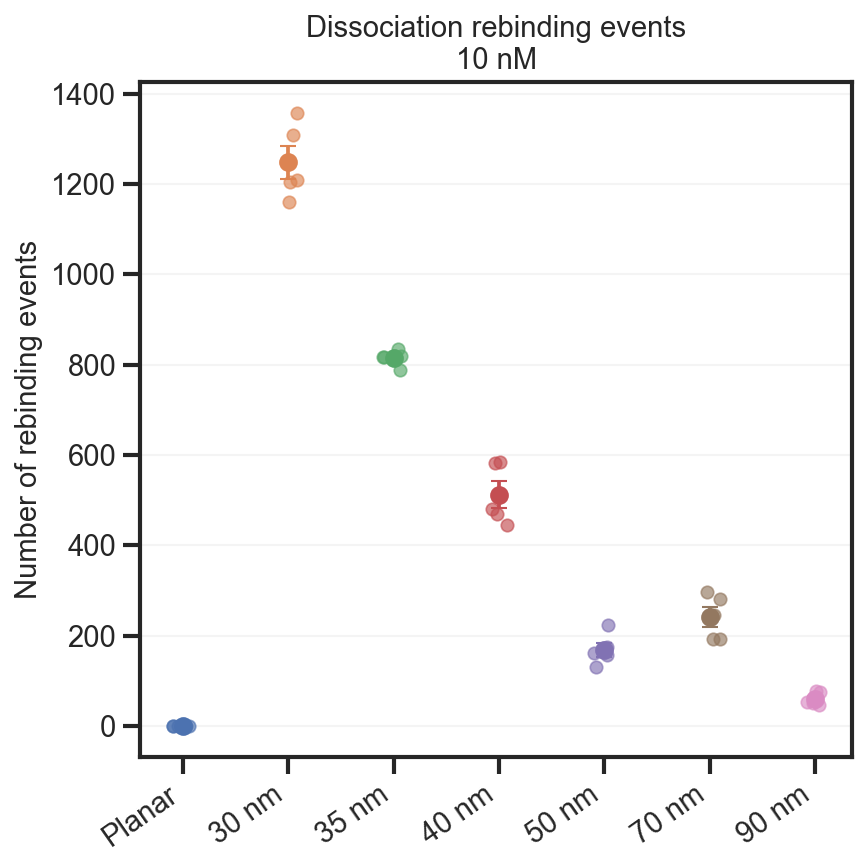

In [38]:
import compare_geometry_rebinding_with_kinetics
importlib.reload(compare_geometry_rebinding_with_kinetics)
from compare_geometry_rebinding_with_kinetics import (
    load_rebinding_and_kinetics,
    plot_rebinding_comparison
)

data = load_rebinding_and_kinetics(
    nanopore_root="/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260806 Nanopore Geometry Sweep",
    planar_root="/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep",
    nanopore_kinetics_csv="//Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260806 Nanopore Geometry Sweep/1to1_kinetics.csv",
    planar_kinetics_csv="/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260812 Planar Concentration Sweep/1to1_kinetics.csv",
    concentration_M=10e-9,
)

fig, ax = plot_rebinding_comparison(
    data,
    phase="dissociation",
    figsize=(6, 6),
)

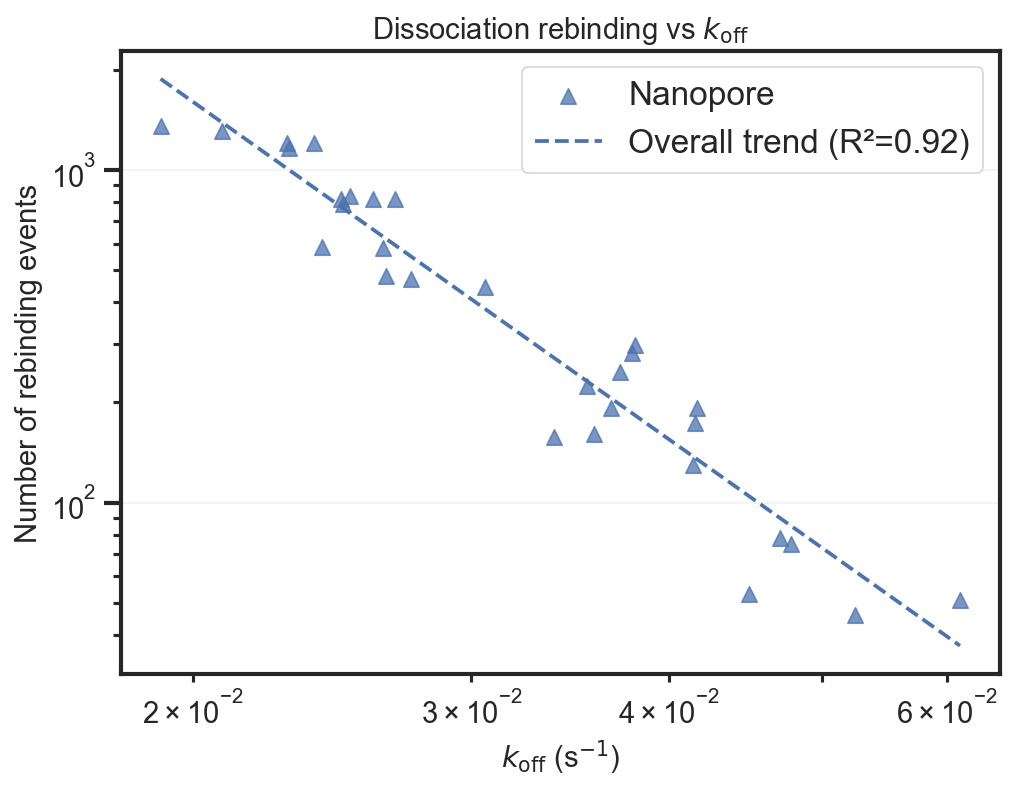

In [40]:
from compare_geometry_rebinding_with_kinetics import (
    plot_rebinding_vs_kinetic_parameter,
)

fig, ax = plot_rebinding_vs_kinetic_parameter(
    data,
    parameter="k_off",
    phase="dissociation",
    log_y=True
)